# Comparative Evaluation — RGB Generalist vs Clear-Weather Specialist

**Project:** Autonomous Systems — Perception  
**Dataset:** *Seeing Through Fog*  
**Experiment:** YOLOv8n RGB generalist vs. clear-weather specialist

---

## 1. Objective and experimental design

Both YOLOv8n networks have **already been trained** and their checkpoints are saved. This notebook does not create datasets, train models, or modify model weights. Its only purpose is to load the two saved models and evaluate them.

- **Generalist:** trained using all environmental conditions in the original training split.
- **Clear-weather specialist:** trained using the strict favorable subset (`none` fog, `none` precipitation, `day`, `dry road`).
- **Evaluation:** both models use the exact same original test split (1,933 images), six classes, image size and evaluation settings.

This comparison investigates whether restricting training to favorable conditions changes performance on clear and adverse test scenes.

### Important interpretation limits

The specialist has fewer training images than the generalist. Therefore, any performance difference may be due to both the training-condition diversity and the smaller training set. The original split was random at image level rather than sequence-disjoint, so temporally related scenes may occur across splits. Environmental categories overlap, and small groups (especially rain) require caution.

## 2. Paths, environment and checkpoint verification

The paths below follow the project structure used in the training notebooks. If either checkpoint is missing, stop here and correct the path rather than silently evaluating another file.

In [ ]:
# ============================================================
# 2.1. Imports and paths
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
import torch
import cv2
from ultralytics import YOLO
from IPython.display import display

PROJECT_DIR = Path("/home/maritza/projects/autonomous_vehicle")

DATASET_DIR = PROJECT_DIR / "dataset" / "yolo_dataset"
DATA_YAML = DATASET_DIR / "data.yaml"
TEST_IMAGE_DIR = DATASET_DIR / "images" / "test"
TEST_LABEL_DIR = DATASET_DIR / "labels" / "test"

ENVIRONMENT_CSV = (
    PROJECT_DIR / "outputs" / "stage1_rgb_baseline"
    / "rgb_image_quality_with_environmental_labels.csv"
)

GENERALIST_PATH = (
    PROJECT_DIR / "models" / "yolov8n_rgb" / "best.pt"
)
SPECIALIST_PATH = (
    PROJECT_DIR / "models" / "yolov8n_rgb_clear_weather" / "best.pt"
)

OUTPUT_DIR = PROJECT_DIR / "outputs" / "yolo_model_comparison"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

required_paths = [
    DATA_YAML, TEST_IMAGE_DIR, TEST_LABEL_DIR,
    ENVIRONMENT_CSV, GENERALIST_PATH, SPECIALIST_PATH
]
missing_paths = [path for path in required_paths if not path.exists()]

if missing_paths:
    raise FileNotFoundError(
        "The following required paths are missing:\n"
        + "\n".join(str(path) for path in missing_paths)
    )

with open(DATA_YAML, "r") as file:
    dataset_config = yaml.safe_load(file)

CLASS_NAMES = dataset_config["names"]
if isinstance(CLASS_NAMES, dict):
    CLASS_NAMES = [
        CLASS_NAMES[key]
        for key in sorted(CLASS_NAMES, key=lambda value: int(value))
    ]
else:
    CLASS_NAMES = list(CLASS_NAMES)

TEST_IMAGES = sorted(TEST_IMAGE_DIR.glob("*.png"))
DEVICE = 0 if torch.cuda.is_available() else "cpu"

print("Generalist checkpoint:", GENERALIST_PATH)
print("Specialist checkpoint:", SPECIALIST_PATH)
print("Test images:", len(TEST_IMAGES))
print("Classes:", CLASS_NAMES)
print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

assert len(TEST_IMAGES) == 1933, (
    f"Expected 1,933 original test images; found {len(TEST_IMAGES)}. "
    "Verify that the original test split has not changed."
)

Generalist checkpoint: /home/maritza/projects/autonomous_vehicle/models/yolov8n_rgb/best.pt
Specialist checkpoint: /home/maritza/projects/autonomous_vehicle/models/yolov8n_rgb_clear_weather/best.pt
Test images: 1933
Classes: ['PassengerCar', 'Pedestrian', 'LargeVehicle', 'RidableVehicle', 'Obstacle', 'Vehicle']
Device: 0
GPU: NVIDIA GeForce RTX 5060 Laptop GPU


## 3. Load both trained models

We load `best.pt` from each model's separate folder. No training call is made in this notebook. The two model objects are kept separate so each evaluation result can be attributed to the correct checkpoint.

In [ ]:
# ============================================================
# 3.1. Load saved checkpoints
# ============================================================

generalist_model = YOLO(str(GENERALIST_PATH))
specialist_model = YOLO(str(SPECIALIST_PATH))

print("Both trained models loaded successfully.")
print("Generalist task:", generalist_model.task)
print("Specialist task:", specialist_model.task)

Both trained models loaded successfully.
Generalist task: detect
Specialist task: detect


## 4. Overall test-set evaluation

Run the same Ultralytics validation procedure on the original `test` split for each checkpoint. The primary metrics are Precision, Recall, mAP@0.50 and mAP@0.50:0.95.

`mAP@0.50` allows a predicted box to count as a match at IoU ≥ 0.50. `mAP@0.50:0.95` averages AP over stricter IoU thresholds and is therefore more demanding about localization quality.

In [ ]:
# ============================================================
# 4.1. Evaluate both models on the identical test split
# ============================================================

EVAL_SETTINGS = {
    "data": str(DATA_YAML),
    "split": "test",
    "imgsz": 640,
    "batch": 4,
    "device": DEVICE,
    "workers": 0,
    "plots": True,
    "save_json": False,
    "verbose": True
}

generalist_results = generalist_model.val(
    **EVAL_SETTINGS,
    project=str(OUTPUT_DIR),
    name="generalist_test",
    exist_ok=True
)

specialist_results = specialist_model.val(
    **EVAL_SETTINGS,
    project=str(OUTPUT_DIR),
    name="specialist_test",
    exist_ok=True
)

Ultralytics 8.4.204 🚀 Python-3.12.3 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8151MiB)
Model summary (fused): 73 layers, 3,133,922 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.1±0.0 ms, read: 287.7±267.4 MB/s, size: 2861.7 KB)
val: Scanning /home/maritza/projects/autonomous_vehicle/dataset/yolo_dataset/labels/test... 1933 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1933/1933 32.2it/s 59.9s0.0ss
val: New cache created: /home/maritza/projects/autonomous_vehicle/dataset/yolo_dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 484/484 5.0it/s 1:360.2sss
                   all       1933      15519      0.682      0.388      0.451      0.301
          PassengerCar       1731       7748      0.846      0.734      0.831       0.59
            Pedestrian       1229       6090      0.781      0.601      0.688      0.401
          LargeVehicle        544        

,Model,Precision,Recall,mAP@0.50,mAP@0.50:0.95
0,RGB Generalist,0.6825,0.3877,0.4513,0.3012
1,Clear-Weather Specialist,0.4475,0.2850,0.3182,0.2004


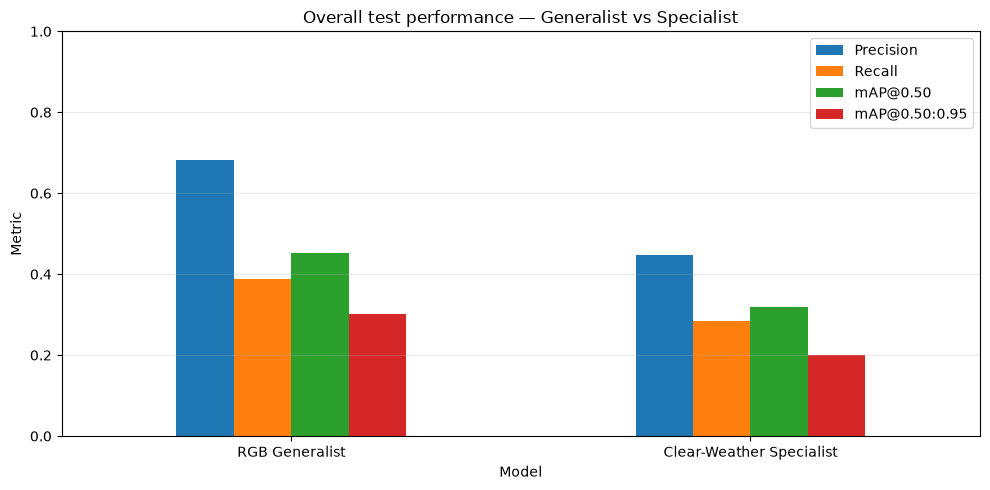

In [ ]:
# ============================================================
# 4.2. Overall metrics comparison
# ============================================================

def extract_overall_metrics(results, model_name):
    return {
        "Model": model_name,
        "Precision": float(results.box.mp),
        "Recall": float(results.box.mr),
        "mAP@0.50": float(results.box.map50),
        "mAP@0.50:0.95": float(results.box.map)
    }

overall_comparison = pd.DataFrame([
    extract_overall_metrics(generalist_results, "RGB Generalist"),
    extract_overall_metrics(specialist_results, "Clear-Weather Specialist")
])

display(overall_comparison.round(4))

ax = overall_comparison.set_index("Model").plot(
    kind="bar", figsize=(10, 5), ylim=(0, 1), rot=0
)
ax.set_title("Overall test performance — Generalist vs Specialist")
ax.set_ylabel("Metric")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

overall_comparison.to_csv(
    OUTPUT_DIR / "overall_metrics_comparison.csv", index=False
)

### Interpretation guide

- Higher **Precision** means a larger fraction of predicted objects are correct.
- Higher **Recall** means a larger fraction of annotated objects are detected.
- Higher **mAP@0.50** indicates better detection ranking and localization at IoU 0.50.
- Higher **mAP@0.50:0.95** indicates stronger localization across stricter overlap criteria.

Do not conclude that one training strategy is universally better from one aggregate score. We next inspect per-class and per-environment results.

## 5. Per-class performance comparison

This section extracts class-wise Precision, Recall, AP@0.50 and AP@0.50:0.95 for both models. It is especially important to inspect `Obstacle` and `Vehicle`, which were weak classes in the original generalist evaluation.

In [ ]:
# ============================================================
# 5.1. Extract per-class metrics robustly
# ============================================================

def extract_per_class(results, model_name, class_names):
    box = results.box
    class_ids = list(map(int, results.ap_class_index))
    rows = []

    for class_id, class_name in enumerate(class_names):
        if class_id in class_ids:
            index = class_ids.index(class_id)
            rows.append({
                "Model": model_name,
                "Class ID": class_id,
                "Class": class_name,
                "Precision": float(box.p[index]),
                "Recall": float(box.r[index]),
                "mAP@0.50": float(box.ap50[index]),
                "mAP@0.50:0.95": float(box.ap[index])
            })
        else:
            rows.append({
                "Model": model_name,
                "Class ID": class_id,
                "Class": class_name,
                "Precision": np.nan,
                "Recall": np.nan,
                "mAP@0.50": np.nan,
                "mAP@0.50:0.95": np.nan
            })

    return pd.DataFrame(rows)

generalist_class_df = extract_per_class(
    generalist_results, "RGB Generalist", CLASS_NAMES
)
specialist_class_df = extract_per_class(
    specialist_results, "Clear-Weather Specialist", CLASS_NAMES
)

per_class_comparison = pd.concat(
    [generalist_class_df, specialist_class_df],
    ignore_index=True
)

display(per_class_comparison.round(4))
per_class_comparison.to_csv(
    OUTPUT_DIR / "per_class_metrics_long.csv", index=False
)

,Model,Class ID,Class,Precision,Recall,mAP@0.50,mAP@0.50:0.95
0,RGB Generalist,0,PassengerCar,0.8461,0.7340,0.8309,0.5904
1,RGB Generalist,1,Pedestrian,0.7811,0.6013,0.6884,0.4013
2,RGB Generalist,2,LargeVehicle,0.7933,0.5507,0.6482,0.4628
3,RGB Generalist,3,RidableVehicle,0.6924,0.4206,0.4915,0.3369
4,RGB Generalist,4,Obstacle,0.3269,0.0118,0.0245,0.0085
5,RGB Generalist,5,Vehicle,0.6551,0.0076,0.0243,0.0071
6,Clear-Weather Specialist,0,PassengerCar,0.7981,0.5560,0.6546,0.4336
7,Clear-Weather Specialist,1,Pedestrian,0.7338,0.5005,0.5669,0.3164
8,Clear-Weather Specialist,2,LargeVehicle,0.5978,0.3180,0.3447,0.2331
9,Clear-Weather Specialist,3,RidableVehicle,0.5556,0.3353,0.3296,0.2153


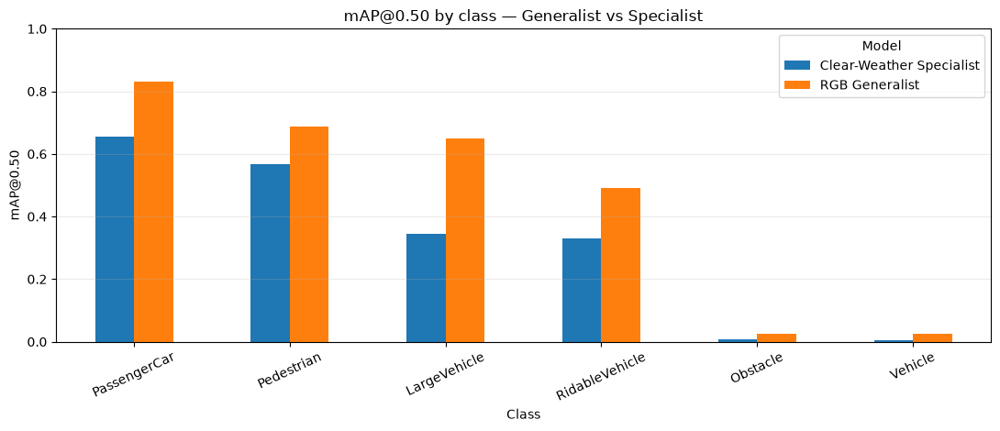

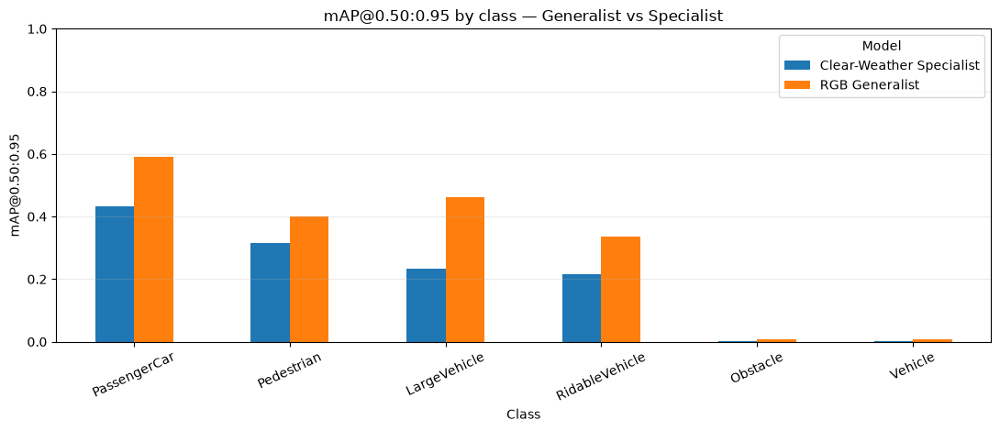

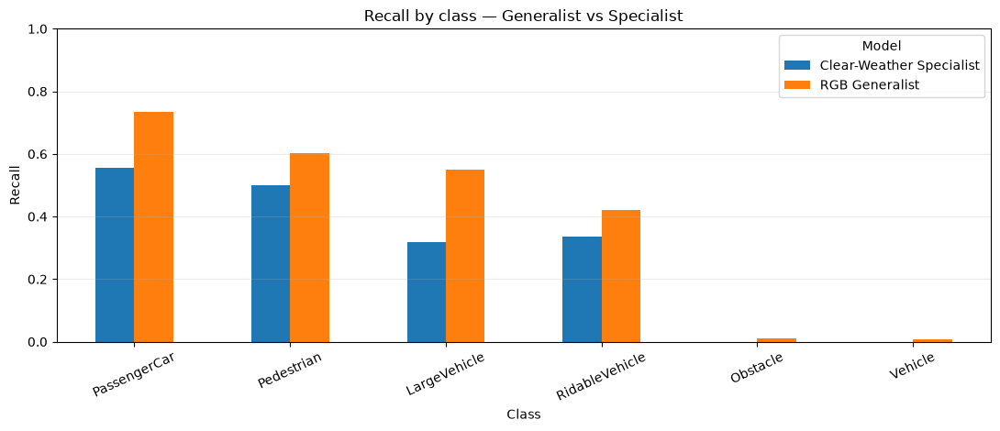

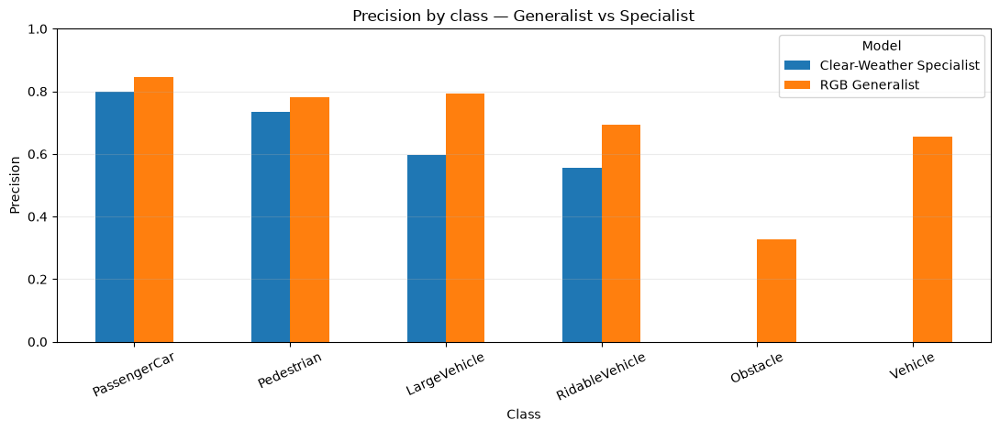

,Specialist - Generalist: Precision,Specialist - Generalist: Recall,Specialist - Generalist: mAP@0.50,Specialist - Generalist: mAP@0.50:0.95
Class,,,,
PassengerCar,-0.0480,-0.1780,-0.1763,-0.1568
Pedestrian,-0.0474,-0.1008,-0.1215,-0.0849
LargeVehicle,-0.1955,-0.2327,-0.3036,-0.2297
RidableVehicle,-0.1368,-0.0853,-0.1619,-0.1216
Obstacle,-0.3269,-0.0118,-0.0167,-0.0062
Vehicle,-0.6551,-0.0076,-0.0183,-0.0056


In [ ]:
# ============================================================
# 5.2. Plot per-class mAP and Recall comparisons
# ============================================================

for metric in ["mAP@0.50", "mAP@0.50:0.95", "Recall", "Precision"]:
    pivot = per_class_comparison.pivot(
        index="Class", columns="Model", values=metric
    ).reindex(CLASS_NAMES)

    ax = pivot.plot(
        kind="bar", figsize=(11, 4.8), ylim=(0, 1), rot=25
    )
    ax.set_title(f"{metric} by class — Generalist vs Specialist")
    ax.set_ylabel(metric)
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

# Specialist minus generalist: positive values favor the specialist.
class_delta = (
    specialist_class_df.set_index("Class")
    [["Precision", "Recall", "mAP@0.50", "mAP@0.50:0.95"]]
    -
    generalist_class_df.set_index("Class")
    [["Precision", "Recall", "mAP@0.50", "mAP@0.50:0.95"]]
)
class_delta = class_delta.add_prefix("Specialist - Generalist: ")
display(class_delta.round(4))
class_delta.to_csv(OUTPUT_DIR / "per_class_metric_deltas.csv")

### Interpretation guide

Positive deltas favor the specialist; negative deltas favor the generalist. Relate class-level changes to the class counts in the specialist's favorable training subset. A low score for a class that had very few favorable training examples may indicate insufficient training coverage rather than an intrinsic inability to detect that class.

## 6. Environmental metadata for the original test split

Join the test filenames to Stage 1 environmental labels. This metadata is descriptive and does not change which images belong to the test set. We require a one-to-one filename match.

In [ ]:
# ============================================================
# 6.1. Build test metadata table
# ============================================================

environment_df = pd.read_csv(ENVIRONMENT_CSV)

filename_candidates = [
    "image_key", "image_filename", "filename", "file_name",
    "image", "image_name", "rgb_filename", "image_path", "path"
]
filename_column = next(
    (column for column in filename_candidates
     if column in environment_df.columns),
    None
)
if filename_column is None:
    raise KeyError(
        f"No filename column found: {environment_df.columns.tolist()}"
    )

environment_df = environment_df.copy()
environment_df["image_key"] = (
    environment_df[filename_column]
    .astype(str)
    .map(lambda value: Path(value).name)
)

environment_columns = [
    "fog_condition", "precipitation_condition",
    "daytime_condition", "twilight", "road_condition"
]

test_metadata = pd.DataFrame({
    "image_key": [path.name for path in TEST_IMAGES],
    "image_path": [str(path.resolve()) for path in TEST_IMAGES]
}).merge(
    environment_df[["image_key"] + environment_columns],
    on="image_key",
    how="left",
    validate="one_to_one"
)

if test_metadata[environment_columns].isna().all(axis=1).any():
    raise ValueError("Some test images have no environmental metadata.")

print("Test metadata rows:", len(test_metadata))
print("Missing labels by dimension:")
display(test_metadata[environment_columns].isna().sum().to_frame("Missing"))

Test metadata rows: 1933
Missing labels by dimension:


,Missing
fog_condition,0
precipitation_condition,0
daytime_condition,0
twilight,0
road_condition,0


## 7. Environmental performance comparison

Evaluate each model on exactly the same image subset for every environmental category. The subset is represented by a text file containing absolute image paths and a temporary YAML file; source images and labels are not copied or modified.

Groups with fewer than 20 images are skipped to avoid presenting extremely unstable subgroup metrics. Note that conditions overlap: an image can belong to both a precipitation group and a nighttime group.

In [ ]:
# ============================================================
# 7.1. Helper to evaluate a model on an image subset
# ============================================================

MIN_GROUP_IMAGES = 20

def evaluate_model_on_subset(model, image_paths, model_tag, group_tag):
    image_paths = [str(Path(path).resolve()) for path in image_paths]
    list_path = OUTPUT_DIR / f"{model_tag}_{group_tag}_images.txt"
    list_path.write_text("\n".join(image_paths) + "\n", encoding="utf-8")

    yaml_path = OUTPUT_DIR / f"{model_tag}_{group_tag}_data.yaml"
    subset_config = {
        "path": str(DATASET_DIR),
        "train": "images/train",
        "val": "images/val",
        "test": str(list_path),
        "nc": len(CLASS_NAMES),
        "names": CLASS_NAMES
    }
    with open(yaml_path, "w", encoding="utf-8") as file:
        yaml.safe_dump(subset_config, file, sort_keys=False)

    result = model.val(
        data=str(yaml_path),
        split="test",
        imgsz=640,
        batch=4,
        device=DEVICE,
        workers=0,
        plots=False,
        save_json=False,
        verbose=False,
        project=str(OUTPUT_DIR),
        name=f"{model_tag}_{group_tag}",
        exist_ok=True
    )

    return {
        "Images": len(image_paths),
        "Precision": float(result.box.mp),
        "Recall": float(result.box.mr),
        "mAP@0.50": float(result.box.map50),
        "mAP@0.50:0.95": float(result.box.map)
    }

In [ ]:
# ============================================================
# 7.2. Evaluate both models by environmental category
# ============================================================

environment_rows = []

for dimension in environment_columns:
    print(f"\nEnvironmental dimension: {dimension}")

    categories = sorted(
        test_metadata[dimension].dropna().unique(),
        key=str
    )

    for category in categories:
        subset = test_metadata.loc[
            test_metadata[dimension] == category
        ]

        if len(subset) < MIN_GROUP_IMAGES:
            print(f"  Skipped {category}: only {len(subset)} images")
            continue

        group_tag = (
            f"{dimension}_{''.join(c if c.isalnum() else '_' for c in str(category))}"
        )

        for model_tag, model in [
            ("generalist", generalist_model),
            ("specialist", specialist_model)
        ]:
            metrics = evaluate_model_on_subset(
                model,
                subset["image_path"].tolist(),
                model_tag,
                group_tag
            )
            environment_rows.append({
                "Dimension": dimension,
                "Condition": str(category),
                "Model": model_tag,
                **metrics
            })

            print(
                f"  {model_tag}: {category}, "
                f"n={metrics['Images']}, "
                f"mAP50={metrics['mAP@0.50']:.3f}"
            )

environment_comparison = pd.DataFrame(environment_rows)
display(environment_comparison.round(4))
environment_comparison.to_csv(
    OUTPUT_DIR / "environmental_metrics_long.csv", index=False
)


Environmental dimension: fog_condition
Ultralytics 8.4.204 🚀 Python-3.12.3 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8151MiB)
Model summary (fused): 73 layers, 3,133,922 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2839.1±1037.2 MB/s, size: 2252.9 KB)
val: Scanning /home/maritza/projects/autonomous_vehicle/dataset/yolo_dataset/labels/test... 174 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 174/174 44.9it/s 3.9s0.4s
val: New cache created: /home/maritza/projects/autonomous_vehicle/dataset/yolo_dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 44/44 6.8it/s 6.5s0.1s
                   all        174        617      0.917      0.465      0.567      0.442
Speed: 0.9ms preprocess, 5.6ms inference, 0.0ms loss, 0.9ms postprocess per image
  generalist: dense, n=174, mAP50=0.567
Ultralytics 8.4.204 🚀 Python-3.12.3 torch-2.15.0+cu132 CUDA:0 (N

,Dimension,Condition,Model,Images,Precision,Recall,mAP@0.50,mAP@0.50:0.95
0,fog_condition,dense,generalist,174,0.9167,0.4648,0.5670,0.4423
1,fog_condition,dense,specialist,174,0.8240,0.3532,0.4164,0.3240
2,fog_condition,light,generalist,300,0.8123,0.4164,0.4711,0.3275
3,fog_condition,light,specialist,300,0.5644,0.2689,0.2891,0.1936
4,fog_condition,none,generalist,1459,0.6897,0.3839,0.4469,0.2950
5,fog_condition,none,specialist,1459,0.6111,0.2906,0.3237,0.2019
6,precipitation_condition,heavy_snow,generalist,172,0.9345,0.4400,0.5424,0.3930
7,precipitation_condition,heavy_snow,specialist,172,0.7549,0.3492,0.3353,0.2270
8,precipitation_condition,light_snow,generalist,540,0.5954,0.3905,0.4484,0.3030
9,precipitation_condition,light_snow,specialist,540,0.5708,0.2654,0.2926,0.1826


,Dimension,Condition,Images,Precision_generalist,Precision_specialist,Recall_generalist,Recall_specialist,mAP@0.50_generalist,mAP@0.50_specialist,mAP@0.50:0.95_generalist,mAP@0.50:0.95_specialist
0,daytime_condition,day,1160,0.6517,0.4634,0.3815,0.3335,0.4497,0.3706,0.3073,0.2423
1,daytime_condition,night,773,0.6133,0.6005,0.4037,0.2164,0.4582,0.2433,0.2953,0.1393
2,fog_condition,dense,174,0.9167,0.8240,0.4648,0.3532,0.5670,0.4164,0.4423,0.3240
3,fog_condition,light,300,0.8123,0.5644,0.4164,0.2689,0.4711,0.2891,0.3275,0.1936
4,fog_condition,none,1459,0.6897,0.6111,0.3839,0.2906,0.4469,0.3237,0.2950,0.2019
5,precipitation_condition,heavy_snow,172,0.9345,0.7549,0.4400,0.3492,0.5424,0.3353,0.3930,0.2270
6,precipitation_condition,light_snow,540,0.5954,0.5708,0.3905,0.2654,0.4484,0.2926,0.3030,0.1826
7,precipitation_condition,none,1192,0.6510,0.6380,0.3859,0.2881,0.4477,0.3290,0.2966,0.2073
8,precipitation_condition,rain,29,0.8490,0.6060,0.3731,0.2387,0.4737,0.2561,0.2928,0.1373
9,road_condition,dry,492,0.7042,0.6570,0.3907,0.3050,0.4525,0.3494,0.3009,0.2248


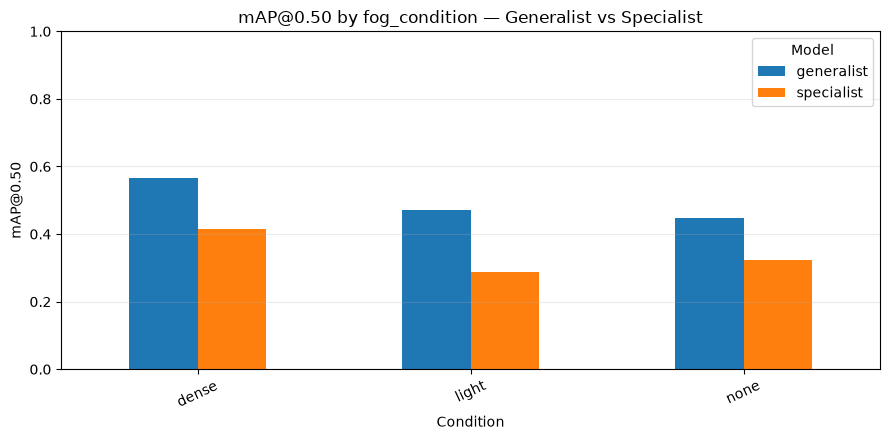

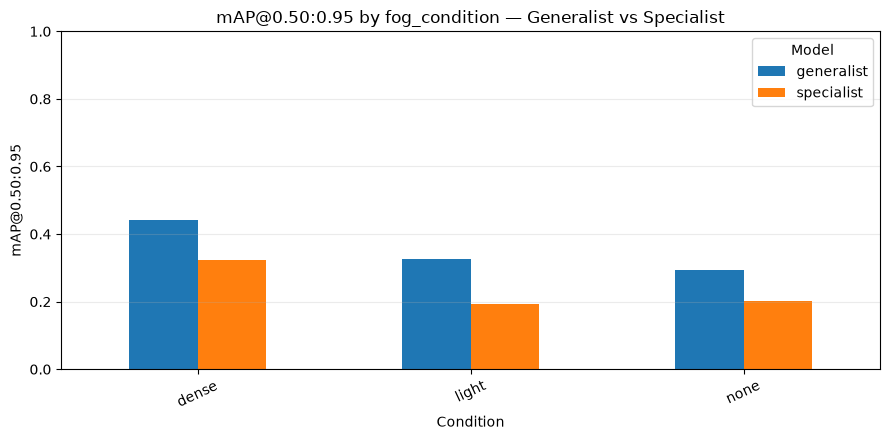

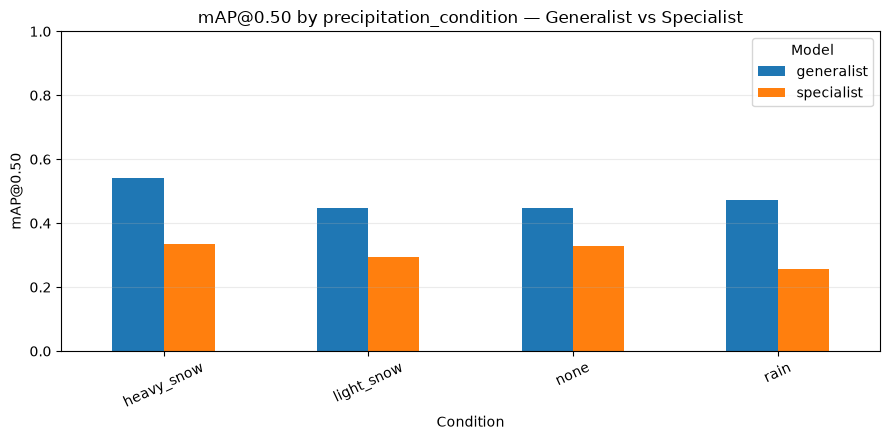

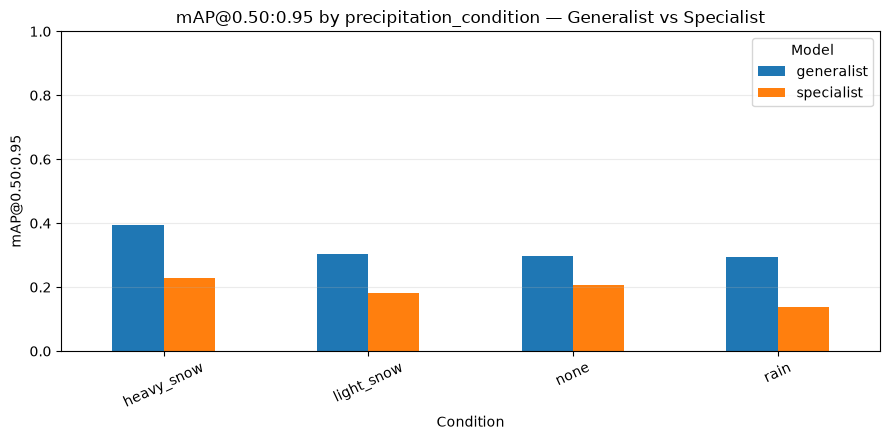

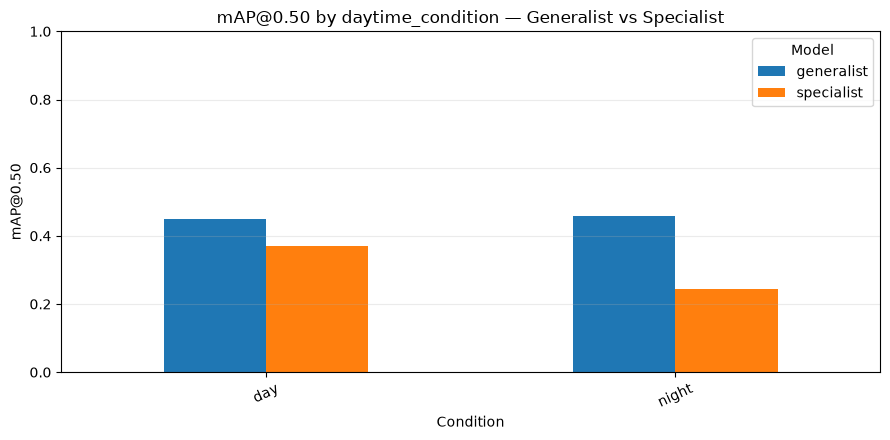

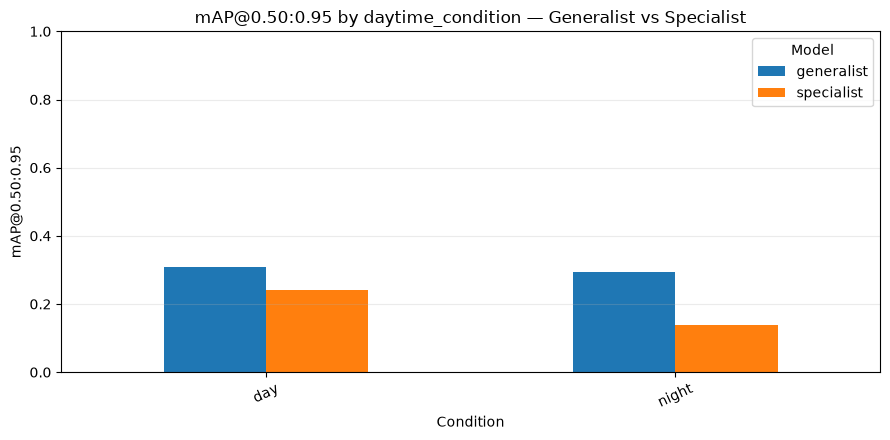

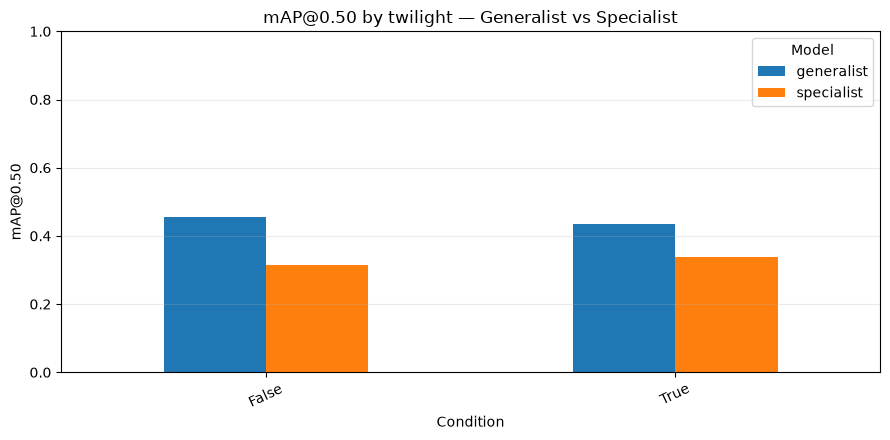

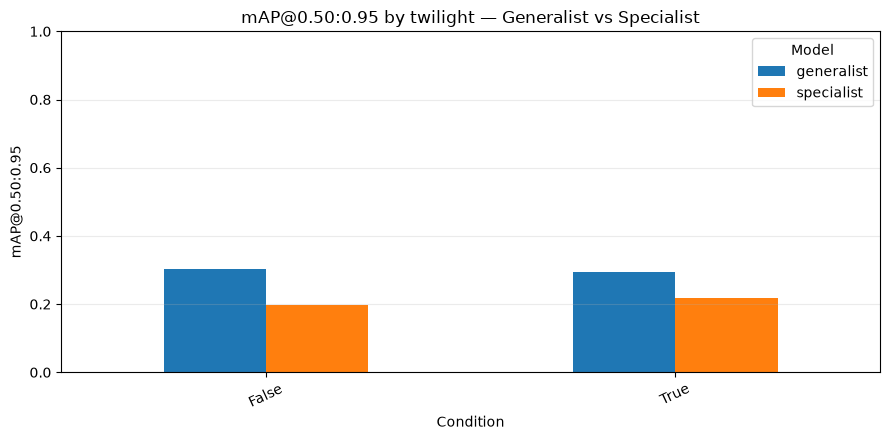

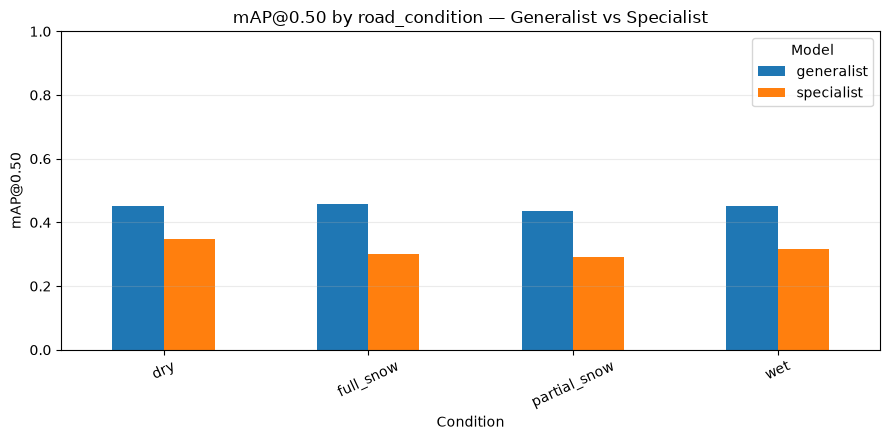

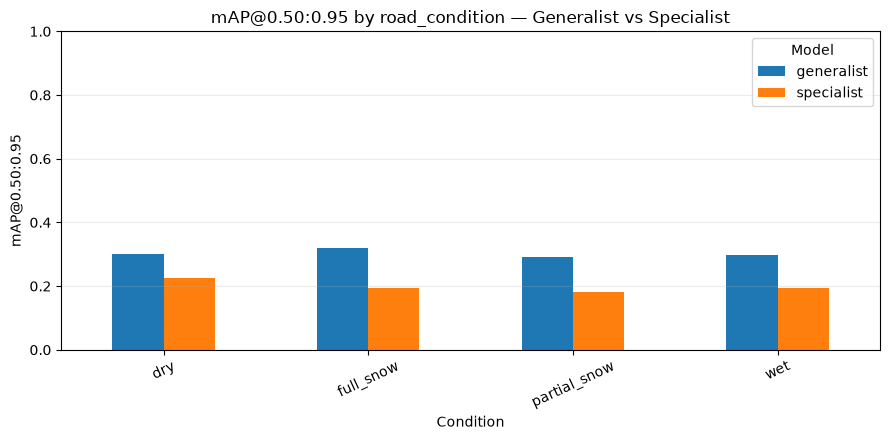

Model,Dimension,Condition,Images,generalist,specialist,Specialist - Generalist mAP@0.50
0,daytime_condition,day,1160,0.4497,0.3706,-0.0791
1,daytime_condition,night,773,0.4582,0.2433,-0.2149
2,fog_condition,dense,174,0.5670,0.4164,-0.1506
3,fog_condition,light,300,0.4711,0.2891,-0.1820
4,fog_condition,none,1459,0.4469,0.3237,-0.1233
5,precipitation_condition,heavy_snow,172,0.5424,0.3353,-0.2071
6,precipitation_condition,light_snow,540,0.4484,0.2926,-0.1558
7,precipitation_condition,none,1192,0.4477,0.3290,-0.1187
8,precipitation_condition,rain,29,0.4737,0.2561,-0.2176
9,road_condition,dry,492,0.4525,0.3494,-0.1030


In [ ]:
# ============================================================
# 7.3. Pivot and plot environmental metric comparisons
# ============================================================

environment_wide = environment_comparison.pivot_table(
    index=["Dimension", "Condition", "Images"],
    columns="Model",
    values=["Precision", "Recall", "mAP@0.50", "mAP@0.50:0.95"]
).reset_index()

# Flatten MultiIndex columns for convenient CSV/report use.
environment_wide.columns = [
    "_".join(str(part) for part in column if str(part))
    if isinstance(column, tuple) else str(column)
    for column in environment_wide.columns
]

display(environment_wide.round(4))
environment_wide.to_csv(
    OUTPUT_DIR / "environmental_metrics_comparison.csv", index=False
)

for dimension in environment_columns:
    dimension_data = environment_comparison[
        environment_comparison["Dimension"] == dimension
    ]

    for metric in ["mAP@0.50", "mAP@0.50:0.95"]:
        pivot = dimension_data.pivot(
            index="Condition", columns="Model", values=metric
        )
        if pivot.empty:
            continue

        ax = pivot.plot(
            kind="bar", figsize=(9, 4.5), ylim=(0, 1), rot=25
        )
        ax.set_title(f"{metric} by {dimension} — Generalist vs Specialist")
        ax.set_ylabel(metric)
        ax.grid(axis="y", alpha=0.25)
        plt.tight_layout()
        plt.show()

# Compute paired subgroup deltas (specialist minus generalist).
environment_delta = environment_comparison.pivot_table(
    index=["Dimension", "Condition", "Images"],
    columns="Model",
    values="mAP@0.50"
).reset_index()

environment_delta["Specialist - Generalist mAP@0.50"] = (
    environment_delta["specialist"] - environment_delta["generalist"]
)
display(environment_delta.round(4))
environment_delta.to_csv(
    OUTPUT_DIR / "environmental_map50_deltas.csv", index=False
)

### Interpretation guide

The most useful pattern is the specialist-minus-generalist difference **within the same environmental category**:

- Positive delta: specialist has higher mAP for that subgroup.
- Negative delta: generalist has higher mAP for that subgroup.
- Near-zero delta: similar measured performance.

A specialist may perform well on clear daytime dry-road scenes yet degrade on snow, fog or night scenes. That would be consistent with a training-distribution specialization trade-off. However, observed differences are descriptive and can also be influenced by object mix, object scale, scene content and the smaller specialist training set.

## 8. Qualitative error analysis on the same deterministic sample

We use the same random seed and up to 250 original test images for both models. The diagnostic matcher uses class-aware greedy matching at IoU ≥ 0.50. This provides interpretable FP/FN counts at a fixed confidence threshold, but it is not the official mAP calculation.

In [ ]:
# ============================================================
# 8.1. Ground-truth parser, IoU and greedy matching
# ============================================================

def read_yolo_ground_truth(label_path, width, height):
    objects = []
    if not label_path.exists():
        return objects

    for line in label_path.read_text().splitlines():
        values = line.split()
        if len(values) != 5:
            continue

        class_id, xc, yc, bw, bh = map(float, values)
        objects.append({
            "class_id": int(class_id),
            "xyxy": [
                (xc - bw / 2) * width,
                (yc - bh / 2) * height,
                (xc + bw / 2) * width,
                (yc + bh / 2) * height
            ]
        })
    return objects

def box_iou_xyxy(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    intersection = max(0, x2 - x1) * max(0, y2 - y1)
    area_a = max(0, a[2] - a[0]) * max(0, a[3] - a[1])
    area_b = max(0, b[2] - b[0]) * max(0, b[3] - b[1])
    union = area_a + area_b - intersection
    return intersection / union if union > 0 else 0.0

def greedy_match(predictions, ground_truth, iou_threshold=0.50):
    candidates = []

    for pred_idx, pred in enumerate(predictions):
        for gt_idx, gt in enumerate(ground_truth):
            if pred["class_id"] != gt["class_id"]:
                continue

            overlap = box_iou_xyxy(pred["xyxy"], gt["xyxy"])
            if overlap >= iou_threshold:
                candidates.append((overlap, pred_idx, gt_idx))

    candidates.sort(reverse=True)
    used_predictions, used_ground_truth = set(), set()
    matches = []

    for overlap, pred_idx, gt_idx in candidates:
        if pred_idx in used_predictions or gt_idx in used_ground_truth:
            continue
        used_predictions.add(pred_idx)
        used_ground_truth.add(gt_idx)
        matches.append((pred_idx, gt_idx, overlap))

    return matches

In [ ]:
# ============================================================
# 8.2. Run both models on identical sample images
# ============================================================

SAMPLE_SIZE = min(250, len(TEST_IMAGES))
CONFIDENCE_THRESHOLD = 0.25
IOU_MATCH_THRESHOLD = 0.50

rng = np.random.default_rng(42)
sample_indices = np.sort(
    rng.choice(len(TEST_IMAGES), size=SAMPLE_SIZE, replace=False)
)
sample_paths = [TEST_IMAGES[index] for index in sample_indices]

def run_sample_diagnostics(model, model_tag):
    records = []

    for start in range(0, len(sample_paths), 8):
        batch_paths = sample_paths[start:start + 8]

        batch_predictions = model.predict(
            source=[str(path) for path in batch_paths],
            imgsz=640,
            conf=CONFIDENCE_THRESHOLD,
            batch=4,
            device=DEVICE,
            verbose=False
        )

        for image_path, result in zip(batch_paths, batch_predictions):
            image = cv2.imread(str(image_path))
            if image is None:
                raise ValueError(f"Could not read image: {image_path}")

            height, width = image.shape[:2]
            ground_truth = read_yolo_ground_truth(
                TEST_LABEL_DIR / f"{image_path.stem}.txt",
                width, height
            )

            predictions = []
            if result.boxes is not None:
                for box in result.boxes:
                    predictions.append({
                        "class_id": int(box.cls.item()),
                        "confidence": float(box.conf.item()),
                        "xyxy": box.xyxy[0].cpu().numpy().tolist()
                    })

            matches = greedy_match(
                predictions, ground_truth, IOU_MATCH_THRESHOLD
            )

            records.append({
                "Model": model_tag,
                "image_key": image_path.name,
                "image_path": image_path,
                "ground_truth": ground_truth,
                "predictions": predictions,
                "matches": matches,
                "TP": len(matches),
                "FP": len(predictions) - len(matches),
                "FN": len(ground_truth) - len(matches)
            })

    return records

generalist_diagnostics = run_sample_diagnostics(
    generalist_model, "Generalist"
)
specialist_diagnostics = run_sample_diagnostics(
    specialist_model, "Specialist"
)

print("Generalist diagnostic images:", len(generalist_diagnostics))
print("Specialist diagnostic images:", len(specialist_diagnostics))

Generalist diagnostic images: 250
Specialist diagnostic images: 250


In [ ]:
# ============================================================
# 8.3. Compare sampled FP/FN counts per image
# ============================================================

def diagnostics_to_dataframe(records):
    return pd.DataFrame([
        {
            "Model": record["Model"],
            "Image": record["image_key"],
            "Ground-truth objects": len(record["ground_truth"]),
            "Predictions": len(record["predictions"]),
            "TP": record["TP"],
            "False positives": record["FP"],
            "False negatives": record["FN"],
            "Total errors": record["FP"] + record["FN"]
        }
        for record in records
    ])

generalist_error_df = diagnostics_to_dataframe(generalist_diagnostics)
specialist_error_df = diagnostics_to_dataframe(specialist_diagnostics)

sample_error_comparison = generalist_error_df.merge(
    specialist_error_df,
    on=["Image", "Ground-truth objects"],
    suffixes=("_Generalist", "_Specialist"),
    validate="one_to_one"
)

display(
    sample_error_comparison.sort_values(
        "Total errors_Specialist", ascending=False
    ).head(20)
)

sample_error_comparison.to_csv(
    OUTPUT_DIR / "sampled_error_comparison.csv", index=False
)

sample_totals = pd.DataFrame([
    {
        "Model": "Generalist",
        "Mean FP/image": generalist_error_df["False positives"].mean(),
        "Mean FN/image": generalist_error_df["False negatives"].mean(),
        "Total FP": generalist_error_df["False positives"].sum(),
        "Total FN": generalist_error_df["False negatives"].sum()
    },
    {
        "Model": "Specialist",
        "Mean FP/image": specialist_error_df["False positives"].mean(),
        "Mean FN/image": specialist_error_df["False negatives"].mean(),
        "Total FP": specialist_error_df["False positives"].sum(),
        "Total FN": specialist_error_df["False negatives"].sum()
    }
])
display(sample_totals.round(3))

,Model_Generalist,Image,Ground-truth objects,Predictions_Generalist,TP_Generalist,False positives_Generalist,False negatives_Generalist,Total errors_Generalist,Model_Specialist,Predictions_Specialist,TP_Specialist,False positives_Specialist,False negatives_Specialist,Total errors_Specialist
202,Generalist,2018-12-21_16-44-04_01500.png,22,26,16,10,6,16,Specialist,16,8,8,14,22
62,Generalist,2018-02-10_14-28-59_00400.png,17,8,4,4,13,17,Specialist,8,2,6,15,21
123,Generalist,2018-12-10_08-55-01_00800.png,21,13,12,1,9,10,Specialist,11,7,4,14,18
209,Generalist,2018-12-22_14-52-12_04300.png,26,22,20,2,6,8,Specialist,29,19,10,7,17
184,Generalist,2018-12-20_14-29-47_01500.png,20,13,9,4,11,15,Specialist,13,8,5,12,17
249,Generalist,2019-09-11_20-13-20_00270.png,15,15,9,6,6,12,Specialist,6,2,4,13,17
20,Generalist,2018-02-06_13-34-24_00100.png,19,11,8,3,11,14,Specialist,12,7,5,12,17
0,Generalist,2018-02-03_22-02-09_00300.png,14,9,6,3,8,11,Specialist,8,3,5,11,16
189,Generalist,2018-12-20_15-26-55_00800.png,18,17,11,6,7,13,Specialist,8,5,3,13,16
182,Generalist,2018-12-19_16-32-40_00000.png,19,15,11,4,8,12,Specialist,3,3,0,16,16


,Model,Mean FP/image,Mean FN/image,Total FP,Total FN
0,Generalist,1.452,2.528,363,632
1,Specialist,1.524,3.756,381,939


## 9. Save outputs and prepare the engineering conclusions

All output files are saved separately from the individual training runs. The final report should distinguish full-test official metrics from the 250-image diagnostic sample.

In [ ]:
# ============================================================
# 9.1. Save overall and per-class comparison tables
# ============================================================

overall_comparison.to_csv(
    OUTPUT_DIR / "overall_metrics_comparison.csv", index=False
)
per_class_comparison.to_csv(
    OUTPUT_DIR / "per_class_metrics_long.csv", index=False
)
sample_totals.to_csv(
    OUTPUT_DIR / "sampled_error_totals.csv", index=False
)

print("Evaluation outputs saved to:", OUTPUT_DIR)
for path in sorted(OUTPUT_DIR.glob("*.csv")):
    print("-", path.name)

Evaluation outputs saved to: /home/maritza/projects/autonomous_vehicle/outputs/yolo_model_comparison
- environmental_map50_deltas.csv
- environmental_metrics_comparison.csv
- environmental_metrics_long.csv
- overall_metrics_comparison.csv
- per_class_metric_deltas.csv
- per_class_metrics_long.csv
- sampled_error_comparison.csv
- sampled_error_totals.csv


## 10. Conclusions — complete after inspecting the generated results

Use the actual values from the tables and plots to answer:

1. **Overall:** Which model has higher test mAP@0.50 and mAP@0.50:0.95?
2. **Class-level:** Which classes benefit from specialist training? Which deteriorate? Are the changes consistent in AP and Recall?
3. **Clear conditions:** Does the specialist improve on favorable test scenes?
4. **Adverse conditions:** Does it lose performance in fog, snow, rain, night, twilight or wet roads compared with the generalist?
5. **Error mechanisms:** Does the specialist produce more false negatives, more false positives, or both on the same sampled images?
6. **Training-data limitation:** How much smaller was the specialist's training set, and which classes were underrepresented?
7. **Engineering implication:** Does the evidence motivate a multimodal camera–LiDAR system, and in which conditions/classes might complementary depth information be most useful?

### Reporting cautions

- The 250-image FP/FN analysis is a diagnostic sample, not the full test set.
- Environmental categories overlap; subgroup results are not independent.
- Very small groups (e.g., rain) should not support strong conclusions.
- The specialist differs from the generalist in both environmental diversity and number of training examples.
- The original image-random split may allow correlated frames across train/validation/test.
- A higher mAP in one subgroup does not establish that the environmental condition caused the change.

### Output directory

`outputs/yolo_model_comparison/`

The saved CSV tables and plots can be used in the portfolio report and as the RGB reference before implementing camera–LiDAR fusion.

---

# 11. Engineering interpretation of the first comparison

The first comparison showed that the RGB Generalist achieved higher mAP@0.50 and mAP@0.50:0.95 than the Clear-Weather Specialist in every reported environmental subgroup. The specialist also produced more false negatives (939 vs. 632) and slightly more false positives (381 vs. 363) in the same 250-image diagnostic sample.

This suggests that the generalist learned more transferable visual representations from the broader training distribution. However, it does **not** prove that environmental diversity alone caused the difference: the specialist was trained with fewer images, so training-set size and composition are confounding factors.

A subgroup such as `fog_condition = none` is not necessarily an ideal-weather scene. It may still be nighttime, rainy, snowy, or have a wet road. We therefore need to evaluate the intersection of all four favorable conditions simultaneously.

# 12. Strict ideal-condition evaluation

The strict ideal subset requires all four conditions at once:

- `fog_condition == "none"`
- `precipitation_condition == "none"`
- `daytime_condition == "day"`
- `road_condition == "dry"`

This is the direct test of whether the specialist benefits on the type of conditions used to select its training data.

In [ ]:
# 12.1. Identify strict ideal-condition test images

STRICT_IDEAL_MASK = (
    (test_metadata["fog_condition"].astype(str) == "none")
    & (test_metadata["precipitation_condition"].astype(str) == "none")
    & (test_metadata["daytime_condition"].astype(str) == "day")
    & (test_metadata["road_condition"].astype(str) == "dry")
)
strict_ideal_test = test_metadata.loc[STRICT_IDEAL_MASK].copy()

print("Original test images:", len(test_metadata))
print("Strict ideal-condition test images:", len(strict_ideal_test))
print("Test-set percentage:", round(100 * len(strict_ideal_test) / len(test_metadata), 2), "%")
display(strict_ideal_test.head())

Original test images: 1933
Strict ideal-condition test images: 236
Test-set percentage: 12.21 %


,image_key,image_path,fog_condition,precipitation_condition,daytime_condition,twilight,road_condition
41,2018-02-04_10-00-43_00200.png,/home/maritza/projects/autonomous_vehicle/data...,none,none,day,False,dry
42,2018-02-04_10-02-19_00000.png,/home/maritza/projects/autonomous_vehicle/data...,none,none,day,False,dry
43,2018-02-04_10-02-19_00200.png,/home/maritza/projects/autonomous_vehicle/data...,none,none,day,False,dry
45,2018-02-04_10-03-55_00200.png,/home/maritza/projects/autonomous_vehicle/data...,none,none,day,False,dry
46,2018-02-04_10-06-46_00000.png,/home/maritza/projects/autonomous_vehicle/data...,none,none,day,False,dry


In [ ]:
# 12.2. Evaluate both saved models on exactly the same strict subset

strict_ideal_rows = []
if len(strict_ideal_test):
    for model_tag, model in [
        ("Generalist", generalist_model),
        ("Specialist", specialist_model)
    ]:
        metrics = evaluate_model_on_subset(
            model,
            strict_ideal_test["image_path"].tolist(),
            model_tag.lower(),
            "strict_ideal_test"
        )
        strict_ideal_rows.append({"Model": model_tag, **metrics})

strict_ideal_results_df = pd.DataFrame(strict_ideal_rows)
display(strict_ideal_results_df.round(4))
strict_ideal_results_df.to_csv(
    OUTPUT_DIR / "strict_ideal_condition_metrics.csv", index=False
)

Ultralytics 8.4.204 🚀 Python-3.12.3 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8151MiB)
Model summary (fused): 73 layers, 3,133,922 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1251.4±487.7 MB/s, size: 2737.3 KB)
val: Scanning /home/maritza/projects/autonomous_vehicle/dataset/yolo_dataset/labels/test... 236 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 236/236 30.3it/s 7.8s0.1s
val: New cache created: /home/maritza/projects/autonomous_vehicle/dataset/yolo_dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 59/59 6.6it/s 8.9s0.1s
                   all        236       2726      0.699      0.389       0.46      0.317
Speed: 0.9ms preprocess, 4.9ms inference, 0.0ms loss, 1.0ms postprocess per image
Ultralytics 8.4.204 🚀 Python-3.12.3 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8151MiB)
Model summary (fused): 73 layers, 3,1

,Model,Images,Precision,Recall,mAP@0.50,mAP@0.50:0.95
0,Generalist,236,0.6988,0.3889,0.4603,0.3168
1,Specialist,236,0.6794,0.3892,0.4337,0.2896


**Interpretation:** If the specialist is better on this strict subset, that supports a benefit from specialization on favorable scenes. If the generalist remains better, the specialist did not gain a measurable advantage even on its target domain. Either way, the smaller specialist training set remains an important limitation.

# 13. Training-set size and class-distribution audit

The specialist had fewer training images after applying the four-condition filter. This section counts training images and annotated objects by class in both prepared datasets. It reads existing files only; it does not modify either dataset.

In [ ]:
# 13.1. Verify the two prepared training datasets

GENERALIST_DATASET_DIR = PROJECT_DIR / "dataset" / "yolo_dataset"
SPECIALIST_DATASET_DIR = PROJECT_DIR / "dataset" / "yolo_dataset_clear_weather"

dataset_roots = {
    "Generalist": GENERALIST_DATASET_DIR,
    "Specialist": SPECIALIST_DATASET_DIR
}

for model_name, root in dataset_roots.items():
    image_dir = root / "images" / "train"
    label_dir = root / "labels" / "train"
    if not image_dir.exists() or not label_dir.exists():
        raise FileNotFoundError(f"Missing train images/labels for {model_name}: {root}")
    print(
        f"{model_name}: {len(list(image_dir.glob('*.png')))} images, "
        f"{len(list(label_dir.glob('*.txt')))} label files"
    )

Generalist: 9018 images, 9018 label files
Specialist: 1120 images, 1120 label files


In [ ]:
# 13.2. Count objects per class in each training split

training_rows = []
for model_name, root in dataset_roots.items():
    image_dir = root / "images" / "train"
    label_dir = root / "labels" / "train"
    image_files = list(image_dir.glob("*.png"))
    class_counts = {class_id: 0 for class_id in range(len(CLASS_NAMES))}
    images_with_objects = 0
    total_objects = 0

    for image_path in image_files:
        label_path = label_dir / f"{image_path.stem}.txt"
        if not label_path.exists():
            continue
        lines = [line.strip() for line in label_path.read_text().splitlines() if line.strip()]
        if lines:
            images_with_objects += 1
        for line in lines:
            values = line.split()
            if len(values) != 5:
                continue
            class_id = int(float(values[0]))
            if class_id in class_counts:
                class_counts[class_id] += 1
                total_objects += 1

    for class_id, class_name in enumerate(CLASS_NAMES):
        training_rows.append({
            "Model": model_name,
            "Class": class_name,
            "Training images": len(image_files),
            "Images with objects": images_with_objects,
            "Total objects": total_objects,
            "Class objects": class_counts[class_id]
        })

training_distribution_df = pd.DataFrame(training_rows)
display(training_distribution_df)
training_distribution_df.to_csv(
    OUTPUT_DIR / "training_class_distribution.csv", index=False
)

,Model,Class,Training images,Images with objects,Total objects,Class objects
0,Generalist,PassengerCar,9018,9018,72872,36648
1,Generalist,Pedestrian,9018,9018,72872,27956
2,Generalist,LargeVehicle,9018,9018,72872,3516
3,Generalist,RidableVehicle,9018,9018,72872,1757
4,Generalist,Obstacle,9018,9018,72872,1631
5,Generalist,Vehicle,9018,9018,72872,1364
6,Specialist,PassengerCar,1120,1120,13338,6289
7,Specialist,Pedestrian,1120,1120,13338,5352
8,Specialist,LargeVehicle,1120,1120,13338,462
9,Specialist,RidableVehicle,1120,1120,13338,616


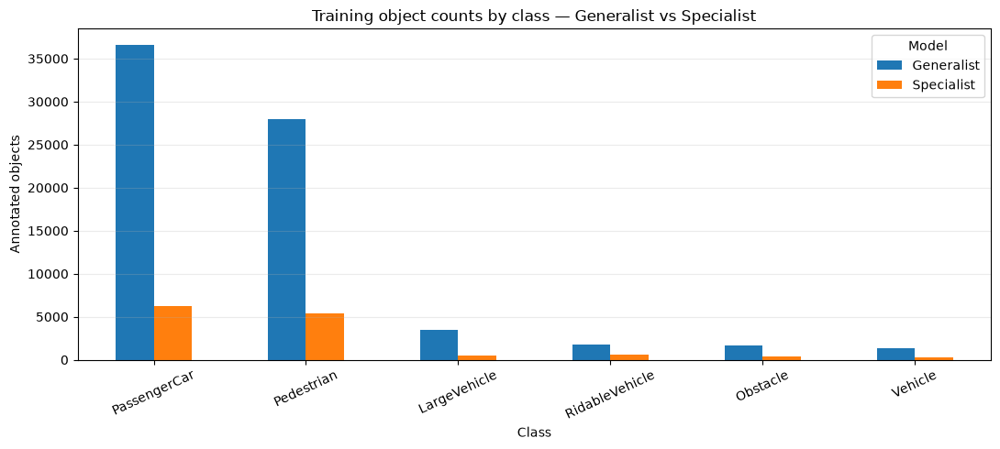

,Training_images,Images_with_objects,Total_objects
Model,,,
Generalist,9018,9018,72872
Specialist,1120,1120,13338


In [ ]:
# 13.3. Visualize the class-count difference

object_count_pivot = training_distribution_df.pivot(
    index="Class", columns="Model", values="Class objects"
).reindex(CLASS_NAMES)

ax = object_count_pivot.plot(kind="bar", figsize=(11, 5), rot=25)
ax.set_title("Training object counts by class — Generalist vs Specialist")
ax.set_ylabel("Annotated objects")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

image_summary = (
    training_distribution_df.groupby("Model")
    .agg(
        Training_images=("Training images", "first"),
        Images_with_objects=("Images with objects", "first"),
        Total_objects=("Total objects", "first")
    )
)
display(image_summary)

**Engineering interpretation:** Compare total image counts and per-class object counts. If the specialist has far fewer examples of a class, its lower test performance may reflect reduced class coverage as well as reduced environmental diversity. These counts do not measure object scale, occlusion, scene diversity, or temporal independence.

# 14. Visual inspection: ground truth and predictions from both models

Metrics summarize performance, but images help explain how the models fail. The gallery below processes the **same test image** with both checkpoints and displays the predictions beside the ground truth.

Color convention:
- Green: ground-truth object matched by a prediction.
- Orange: ground-truth object missed by the model (false negative).
- Blue: prediction matched to a ground-truth object.
- Red: unmatched prediction (false positive).

This makes it easier to inspect missed small/distant objects, crowded scenes, class confusions, and localization differences.

In [ ]:
# 14.1. Select a compact, deterministic set of test images

visual_image_paths = []

# Include up to two strict ideal-condition examples.
if len(strict_ideal_test):
    visual_image_paths.extend(
        Path(p) for p in strict_ideal_test["image_path"].head(2).tolist()
    )

# Add one example from selected adverse conditions where available.
visual_conditions = [
    ("fog_condition", "dense"),
    ("precipitation_condition", "heavy_snow"),
    ("daytime_condition", "night"),
    ("road_condition", "wet")
]
for dimension, condition in visual_conditions:
    candidates = test_metadata.loc[
        test_metadata[dimension].astype(str) == condition, "image_path"
    ].tolist()
    if candidates:
        candidate = Path(candidates[0])
        if candidate not in visual_image_paths:
            visual_image_paths.append(candidate)

visual_image_paths = visual_image_paths[:8]
print("Selected images:", len(visual_image_paths))
for path in visual_image_paths:
    print(path.name)

Selected images: 6
2018-02-04_10-00-43_00200.png
2018-02-04_10-02-19_00000.png
2018-02-07_18-06-31_00120.png
2018-02-04_11-29-22_00000.png
2018-02-03_20-49-38_00000.png
2018-02-03_21-41-51_00100.png


In [10]:
from pathlib import Path
import torch
import cv2
from ultralytics import YOLO

# --------------------------------------------------
# 1. PROJECT PATH
# --------------------------------------------------

PROJECT_ROOT = Path.cwd()

# If the notebook was opened outside the project root,
# locate the project directory using its dataset folder.
if not (PROJECT_ROOT / "dataset" / "yolo_dataset").exists():
    candidates = [
        Path("/home/maritza/projects/autonomous_vehicle"),
        Path.cwd() / "autonomous_vehicle",
    ]

    PROJECT_ROOT = next(
        (p for p in candidates if (p / "dataset" / "yolo_dataset").exists()),
        None
    )

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the autonomous_vehicle project directory."
    )

print("Project root:", PROJECT_ROOT)


# --------------------------------------------------
# 2. TEST DATASET
# --------------------------------------------------

TEST_IMAGE_DIR = PROJECT_ROOT / "dataset/yolo_dataset/images/test"
TEST_LABEL_DIR = PROJECT_ROOT / "dataset/yolo_dataset/labels/test"

if not TEST_IMAGE_DIR.exists():
    raise FileNotFoundError(f"Test image directory not found: {TEST_IMAGE_DIR}")

if not TEST_LABEL_DIR.exists():
    raise FileNotFoundError(f"Test label directory not found: {TEST_LABEL_DIR}")

TEST_IMAGES = sorted([
    p for p in TEST_IMAGE_DIR.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

if len(TEST_IMAGES) == 0:
    raise RuntimeError("No test images were found.")

print("Test images:", len(TEST_IMAGES))
print("Test labels:", len(list(TEST_LABEL_DIR.glob("*.txt"))))


# --------------------------------------------------
# 3. DEVICE
# --------------------------------------------------

DEVICE = 0 if torch.cuda.is_available() else "cpu"

print("Evaluation device:", DEVICE)


# --------------------------------------------------
# 4. MODEL WEIGHT FILES
# --------------------------------------------------

GENERALIST_CANDIDATES = [
    PROJECT_ROOT / "models/yolov8n_rgb/best.pt",
    PROJECT_ROOT / "models/yolov8n_rgb/weights/best.pt",
]

SPECIALIST_CANDIDATES = [
    PROJECT_ROOT / "models/yolov8n_rgb_clear_weather/best.pt",
    PROJECT_ROOT / "models/yolov8n_rgb_clear_weather/weights/best.pt",
]


def find_model_weights(candidates, model_name):
    for path in candidates:
        if path.exists():
            return path

    raise FileNotFoundError(
        f"{model_name} weights not found.\n"
        "Checked these locations:\n"
        + "\n".join(str(p) for p in candidates)
    )


GENERALIST_PATH = find_model_weights(
    GENERALIST_CANDIDATES, "Generalist"
)

SPECIALIST_PATH = find_model_weights(
    SPECIALIST_CANDIDATES, "Specialist"
)

print("Generalist weights:", GENERALIST_PATH)
print("Specialist weights:", SPECIALIST_PATH)


# --------------------------------------------------
# 5. LOAD TRAINED MODELS
# --------------------------------------------------

generalist_model = YOLO(str(GENERALIST_PATH))
specialist_model = YOLO(str(SPECIALIST_PATH))

print("Both trained models loaded successfully.")


# --------------------------------------------------
# 6. FINAL VALIDATION
# --------------------------------------------------

required_variables = [
    "TEST_IMAGES",
    "TEST_LABEL_DIR",
    "DEVICE",
    "generalist_model",
    "specialist_model",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(f"Still missing: {missing_variables}")

print("\nEnvironment ready for Section 14.")

Project root: /home/maritza/projects/autonomous_vehicle
Test images: 1933
Test labels: 1933
Evaluation device: 0
Generalist weights: /home/maritza/projects/autonomous_vehicle/models/yolov8n_rgb/best.pt
Specialist weights: /home/maritza/projects/autonomous_vehicle/models/yolov8n_rgb_clear_weather/best.pt
Both trained models loaded successfully.

Environment ready for Section 14.


All prediction and visualization helpers are ready.

Selected images per category:
-------------------------------------------------------
PassengerCar: 2018-02-03_20-49-38_00000.png
Pedestrian: 2018-02-03_20-57-26_00070.png
LargeVehicle: 2018-02-03_22-02-09_00300.png
RidableVehicle: 2018-02-03_22-07-02_00200.png
Obstacle: 2018-02-03_21-47-17_00200.png
Vehicle: 2018-02-03_21-38-49_00100.png
-------------------------------------------------------
Total selected images: 6 out of 6 categories

Processing category: PassengerCar


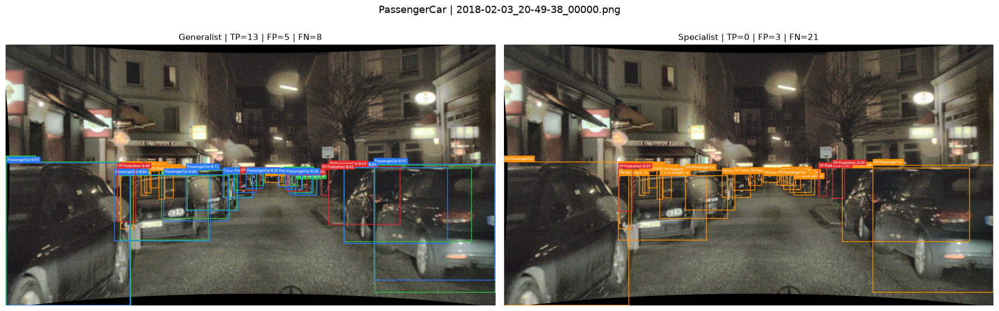


Processing category: Pedestrian


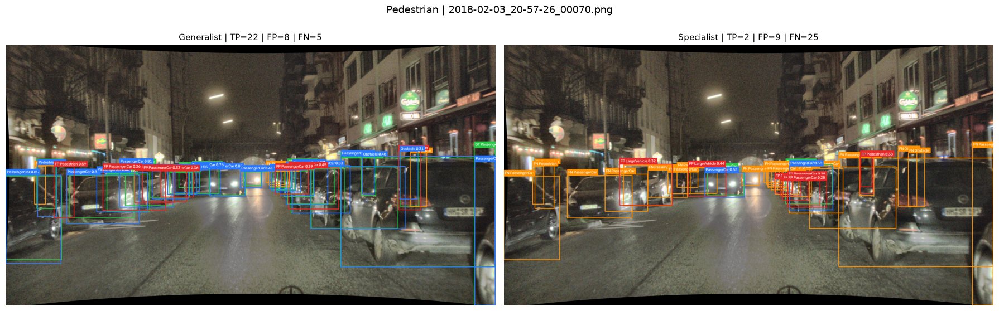


Processing category: LargeVehicle


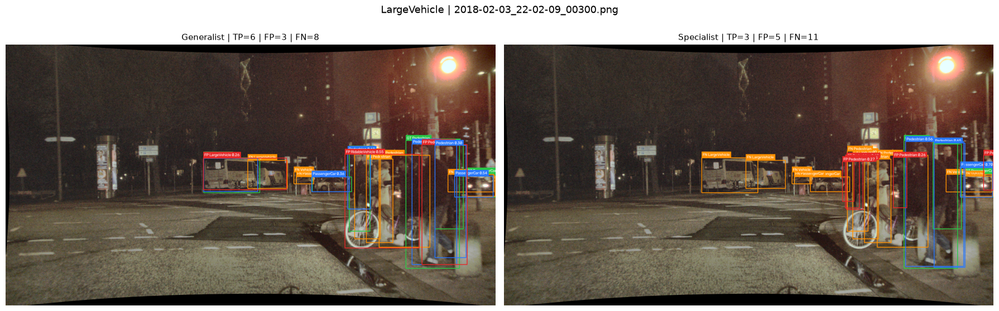


Processing category: RidableVehicle


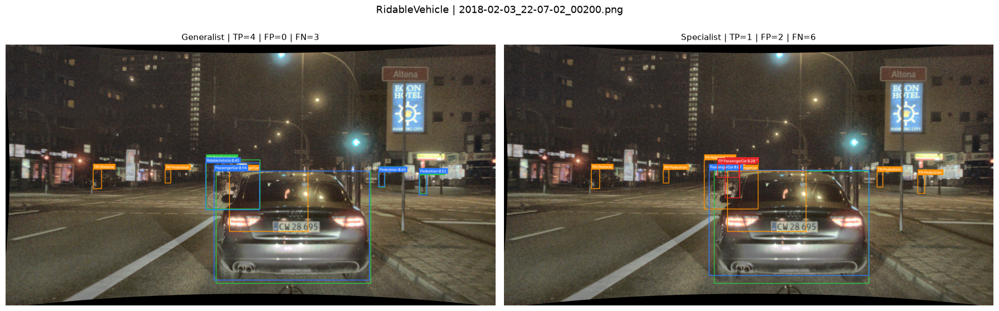


Processing category: Obstacle


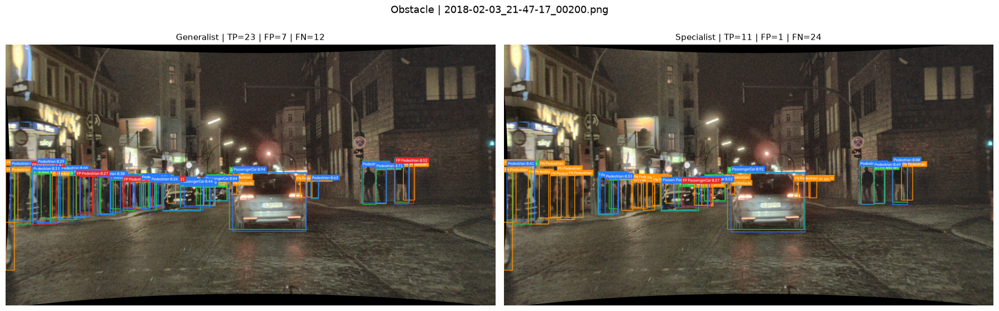


Processing category: Vehicle


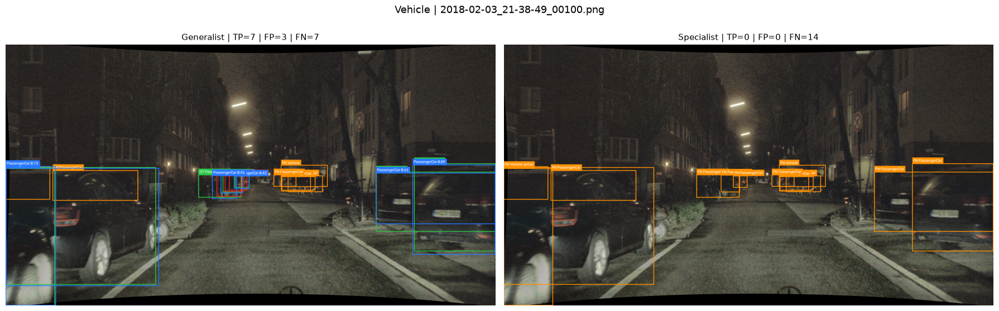


Visual comparison completed.


In [11]:

# ============================================================
# 14.2. PREDICTION, MATCHING AND VISUALIZATION HELPERS
# ============================================================

from pathlib import Path
import cv2
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 14.2.1. Configuration
# ------------------------------------------------------------

CLASS_NAMES = [
    "PassengerCar",
    "Pedestrian",
    "LargeVehicle",
    "RidableVehicle",
    "Obstacle",
    "Vehicle"
]

VISUAL_CONFIDENCE = 0.25
VISUAL_IOU_THRESHOLD = 0.50


# Check required variables before proceeding
required_variables = [
    "TEST_IMAGES",
    "TEST_LABEL_DIR",
    "DEVICE",
    "generalist_model",
    "specialist_model"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        f"Missing required variables: {missing_variables}. "
        "Execute the corresponding setup/model-loading cells first."
    )


# ------------------------------------------------------------
# 14.2.2. Read YOLO ground-truth labels
# ------------------------------------------------------------

def read_yolo_ground_truth(label_path, image_width, image_height):
    """
    Read YOLO-format labels and convert normalized xywh
    coordinates into pixel-based xyxy coordinates.
    """

    label_path = Path(label_path)

    if not label_path.exists():
        raise FileNotFoundError(
            f"Ground-truth file not found: {label_path}"
        )

    ground_truth = []

    with open(label_path, "r") as file:

        for line_number, line in enumerate(file, start=1):

            values = line.strip().split()

            if not values:
                continue

            if len(values) != 5:
                raise ValueError(
                    f"Invalid label format in {label_path}, "
                    f"line {line_number}: {line}"
                )

            class_id, xc, yc, box_width, box_height = map(
                float, values
            )

            class_id = int(class_id)

            if not 0 <= class_id < len(CLASS_NAMES):
                raise ValueError(
                    f"Invalid class ID {class_id} in {label_path}"
                )

            # Convert normalized coordinates to pixels
            xc *= image_width
            yc *= image_height
            box_width *= image_width
            box_height *= image_height

            x1 = xc - box_width / 2
            y1 = yc - box_height / 2
            x2 = xc + box_width / 2
            y2 = yc + box_height / 2

            ground_truth.append({
                "class_id": class_id,
                "xyxy": [x1, y1, x2, y2]
            })

    return ground_truth


# ------------------------------------------------------------
# 14.2.3. Calculate Intersection over Union
# ------------------------------------------------------------

def calculate_box_iou(box_a, box_b):
    """Calculate IoU between two xyxy bounding boxes."""

    x1 = max(box_a[0], box_b[0])
    y1 = max(box_a[1], box_b[1])
    x2 = min(box_a[2], box_b[2])
    y2 = min(box_a[3], box_b[3])

    intersection = (
        max(0, x2 - x1) *
        max(0, y2 - y1)
    )

    area_a = (
        max(0, box_a[2] - box_a[0]) *
        max(0, box_a[3] - box_a[1])
    )

    area_b = (
        max(0, box_b[2] - box_b[0]) *
        max(0, box_b[3] - box_b[1])
    )

    union = area_a + area_b - intersection

    if union <= 0:
        return 0.0

    return intersection / union


# ------------------------------------------------------------
# 14.2.4. Greedy class-aware matching
# ------------------------------------------------------------

def greedy_match(predictions, ground_truth, iou_threshold=0.50):
    """
    Match predictions to ground-truth objects.

    Matching requires:
    - Same class
    - IoU >= threshold
    - One-to-one assignment

    Returns:
        List of (pred_id, gt_id, iou) tuples.
    """

    candidates = []

    for pred_id, prediction in enumerate(predictions):

        for gt_id, gt in enumerate(ground_truth):

            if prediction["class_id"] != gt["class_id"]:
                continue

            iou = calculate_box_iou(
                prediction["xyxy"],
                gt["xyxy"]
            )

            if iou >= iou_threshold:
                candidates.append((iou, pred_id, gt_id))

    # Highest IoU candidates are considered first
    candidates.sort(
        key=lambda item: item[0],
        reverse=True
    )

    matches = []
    matched_pred_ids = set()
    matched_gt_ids = set()

    for iou, pred_id, gt_id in candidates:

        if pred_id in matched_pred_ids:
            continue

        if gt_id in matched_gt_ids:
            continue

        matches.append((pred_id, gt_id, iou))

        matched_pred_ids.add(pred_id)
        matched_gt_ids.add(gt_id)

    return matches


# ------------------------------------------------------------
# 14.2.5. Draw bounding boxes and labels
# ------------------------------------------------------------

def annotate_box(image_rgb, xyxy, color, label):
    """Draw a bounding box and a filled label background."""

    height, width = image_rgb.shape[:2]

    x1, y1, x2, y2 = map(int, xyxy)

    x1 = max(0, min(x1, width - 1))
    x2 = max(0, min(x2, width - 1))
    y1 = max(0, min(y1, height - 1))
    y2 = max(0, min(y2, height - 1))

    cv2.rectangle(
        image_rgb,
        (x1, y1),
        (x2, y2),
        color,
        thickness=2
    )

    font = cv2.FONT_HERSHEY_SIMPLEX
    font_scale = 0.5
    thickness = 1

    (text_width, text_height), baseline = cv2.getTextSize(
        label,
        font,
        font_scale,
        thickness
    )

    label_top = max(
        0,
        y1 - text_height - baseline - 6
    )

    label_bottom = min(
        height - 1,
        label_top + text_height + baseline + 6
    )

    label_right = min(
        width - 1,
        x1 + text_width + 8
    )

    cv2.rectangle(
        image_rgb,
        (x1, label_top),
        (label_right, label_bottom),
        color,
        thickness=-1
    )

    cv2.putText(
        image_rgb,
        label,
        (x1 + 4, label_bottom - baseline - 3),
        font,
        font_scale,
        (255, 255, 255),
        thickness,
        lineType=cv2.LINE_AA
    )


# ------------------------------------------------------------
# 14.2.6. Run inference and match one image
# ------------------------------------------------------------

def predict_and_match_one(
    model,
    image_path,
    confidence=VISUAL_CONFIDENCE,
    iou_threshold=VISUAL_IOU_THRESHOLD
):
    """
    Run YOLO inference and match predictions against ground truth.
    """

    image_path = Path(image_path)

    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(
            f"Could not read image: {image_path}"
        )

    height, width = image.shape[:2]

    label_path = (
        Path(TEST_LABEL_DIR) /
        f"{image_path.stem}.txt"
    )

    ground_truth = read_yolo_ground_truth(
        label_path,
        width,
        height
    )

    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=confidence,
        device=DEVICE,
        verbose=False
    )[0]

    predictions = []

    if result.boxes is not None:

        for box in result.boxes:

            predictions.append({
                "class_id": int(box.cls.item()),
                "confidence": float(box.conf.item()),
                "xyxy": box.xyxy[0].cpu().numpy().tolist()
            })

    matches = greedy_match(
        predictions,
        ground_truth,
        iou_threshold
    )

    matched_pred_ids = {
        pred_id
        for pred_id, _, _ in matches
    }

    matched_gt_ids = {
        gt_id
        for _, gt_id, _ in matches
    }

    return (
        image,
        ground_truth,
        predictions,
        matched_pred_ids,
        matched_gt_ids
    )


# ------------------------------------------------------------
# 14.2.7. Draw model comparison
# ------------------------------------------------------------

def draw_model_comparison(
    image_bgr,
    ground_truth,
    predictions,
    matched_pred_ids,
    matched_gt_ids
):
    """
    Visualize ground truth and predictions.

    Colors:
    - Green: matched ground truth
    - Orange: missed ground truth (FN)
    - Blue: matched prediction
    - Red: unmatched prediction (FP)
    """

    image_rgb = cv2.cvtColor(
        image_bgr.copy(),
        cv2.COLOR_BGR2RGB
    )

    # Draw ground-truth objects
    for gt_id, obj in enumerate(ground_truth):

        matched = gt_id in matched_gt_ids

        color = (
            (40, 200, 70)
            if matched
            else (255, 145, 0)
        )

        class_name = CLASS_NAMES[obj["class_id"]]

        label = (
            f"GT {class_name}"
            if matched
            else f"FN {class_name}"
        )

        annotate_box(
            image_rgb,
            obj["xyxy"],
            color,
            label
        )

    # Draw model predictions
    for pred_id, pred in enumerate(predictions):

        matched = pred_id in matched_pred_ids

        color = (
            (40, 120, 255)
            if matched
            else (230, 40, 40)
        )

        class_name = CLASS_NAMES[pred["class_id"]]

        label = (
            f"{class_name} {pred['confidence']:.2f}"
        )

        if not matched:
            label = f"FP {label}"

        annotate_box(
            image_rgb,
            pred["xyxy"],
            color,
            label
        )

    return image_rgb


print("All prediction and visualization helpers are ready.")


# ============================================================
# 14.3. SELECT ONE IMAGE PER OBJECT CATEGORY
# ============================================================

visual_images_by_class = {}
used_images = set()

for class_id, class_name in enumerate(CLASS_NAMES):

    for image_path in TEST_IMAGES:

        image_path = Path(image_path)

        if image_path in used_images:
            continue

        label_path = (
            Path(TEST_LABEL_DIR) /
            f"{image_path.stem}.txt"
        )

        if not label_path.exists():
            continue

        with open(label_path, "r") as file:

            image_class_ids = {
                int(line.split()[0])
                for line in file
                if line.strip()
            }

        if class_id in image_class_ids:

            visual_images_by_class[class_name] = image_path
            used_images.add(image_path)

            break


visual_image_paths = list(
    visual_images_by_class.values()
)

print("\nSelected images per category:")
print("-" * 55)

for class_name in CLASS_NAMES:

    image_path = visual_images_by_class.get(class_name)

    if image_path is not None:
        print(f"{class_name}: {image_path.name}")
    else:
        print(f"{class_name}: No image found")

print("-" * 55)

print(
    f"Total selected images: {len(visual_image_paths)} "
    f"out of {len(CLASS_NAMES)} categories"
)


# ============================================================
# 14.4. SIDE-BY-SIDE VISUAL COMPARISON
# ============================================================

for class_name, image_path in visual_images_by_class.items():

    print(f"\nProcessing category: {class_name}")

    # Generalist inference
    generalist_data = predict_and_match_one(
        generalist_model,
        image_path
    )

    # Specialist inference
    specialist_data = predict_and_match_one(
        specialist_model,
        image_path
    )

    image_g, gt_g, pred_g, mp_g, mg_g = generalist_data
    image_s, gt_s, pred_s, mp_s, mg_s = specialist_data

    # Draw visual results
    visual_g = draw_model_comparison(
        image_g,
        gt_g,
        pred_g,
        mp_g,
        mg_g
    )

    visual_s = draw_model_comparison(
        image_s,
        gt_s,
        pred_s,
        mp_s,
        mg_s
    )

    # Calculate TP, FP and FN
    tp_g = len(mp_g)
    fp_g = len(pred_g) - tp_g
    fn_g = len(gt_g) - len(mg_g)

    tp_s = len(mp_s)
    fp_s = len(pred_s) - tp_s
    fn_s = len(gt_s) - len(mg_s)

    # Create side-by-side figure
    fig, axes = plt.subplots(
        1,
        2,
        figsize=(18, 6)
    )

    axes[0].imshow(visual_g)

    axes[0].set_title(
        f"Generalist | TP={tp_g} | FP={fp_g} | FN={fn_g}",
        fontsize=11
    )

    axes[0].axis("off")

    axes[1].imshow(visual_s)

    axes[1].set_title(
        f"Specialist | TP={tp_s} | FP={fp_s} | FN={fn_s}",
        fontsize=11
    )

    axes[1].axis("off")

    fig.suptitle(
        f"{class_name} | {image_path.name}",
        fontsize=13
    )

    plt.tight_layout()
    plt.show()


print("\nVisual comparison completed.")


### How to interpret the gallery

The same scene is shown for both models, so differences in the panels come from their predictions. Look for objects detected by the generalist but missed by the specialist, false detections, and localization differences. Note that overlapping boxes are possible because ground-truth and prediction boxes are drawn together.

Visual examples support error interpretation; they do not establish statistical significance or prove that LiDAR will resolve a given failure.